# Exercise 5

In [1]:
import numpy as np

In [8]:
def update_assignments(data, centroids):
    labels = []
    for i in range(data.shape[1]):
        di = [np.sqrt(np.sum((data[:, i] - centroids[k])**2)) for k in range(len(centroids))]
        labels.append(np.argmin(di))
    return np.array(labels)
 
def update_centroids(data, old_centroids, assignments):
    new_centroids = []
    for i in range(len(old_centroids)):
        ind_i = np.argwhere(assignments == i).flatten()
        new_centroids.append(np.mean(data[:, ind_i], axis=1))
    return np.array(new_centroids)

In [9]:
data = np.loadtxt('blobs.dat')

In [10]:
centroids = data[:, :3].T
labels = []
for i in range(5):
    labels = update_assignments(data, centroids)
    update_centroids(data, centroids, labels)
labels

array([0, 1, 2, 0, 1, 0, 1, 1, 0, 0, 0, 2, 1, 0, 1, 2, 1, 2, 2, 1, 0, 2,
       2, 0, 1, 1, 0, 2, 1, 0, 0, 2, 2, 0, 2, 1, 1, 2, 1, 2, 1, 2, 2, 2,
       2, 0, 0, 0, 1, 1])

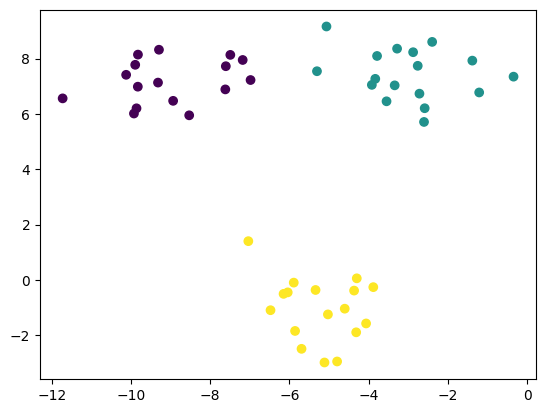

In [11]:
import matplotlib.pyplot as plt 
plt.scatter(data[0, :], data[1, :], c=labels)

# 5.2

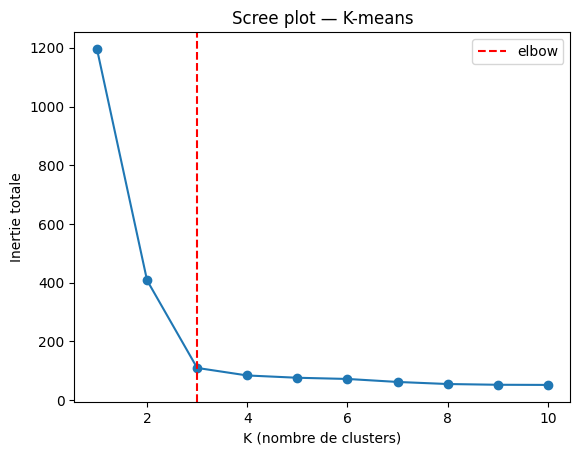

In [17]:
def compute_inertia(data, centroids, labels):
    inertia = 0
    for k in range(len(centroids)):
        points_in_cluster = data[:, labels == k]
        inertia += np.sum((points_in_cluster - centroids[k:k+1].T)**2)
    return inertia

# Scree plot
inertias = []

for k in range(1, 11):
    centroids = data[:, :k].T
    labels = np.zeros(data.shape[1], dtype=int)
    for i in range(10):
        labels = update_assignments(data, centroids)
        centroids = update_centroids(data, centroids, labels)
    inertias.append(compute_inertia(data, centroids, labels))

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel("K (nombre de clusters)")
plt.ylabel("Inertie totale")
plt.title("Scree plot — K-means")
plt.axvline(x=3, color='red', linestyle='--', label='elbow')
plt.legend()
plt.show()

The elbow is clearly at K=3 which is in fact the best choice.